In [1]:
library(tidyverse)

suppressPackageStartupMessages(library(limma))
suppressPackageStartupMessages(library(edgeR))
suppressPackageStartupMessages(library(DESeq2))

suppressPackageStartupMessages(library(pheatmap))
suppressPackageStartupMessages(library(ComplexHeatmap))

suppressPackageStartupMessages(library(ggrepel))
suppressPackageStartupMessages(library(patchwork))
suppressPackageStartupMessages(library(circlize))
suppressPackageStartupMessages(library(RColorBrewer))

── Attaching core tidyverse packages ──────────────────────────────────────────────────────────────── tidyverse 2.0.0 ──
✔ dplyr     1.1.4     ✔ readr     2.1.5
✔ forcats   1.0.0     ✔ stringr   1.5.1
✔ ggplot2   3.5.2     ✔ tibble    3.2.1
✔ lubridate 1.9.4     ✔ tidyr     1.3.1
✔ purrr     1.0.4     
── Conflicts ────────────────────────────────────────────────────────────────────────────────── tidyverse_conflicts() ──
✖ dplyr::filter() masks stats::filter()
✖ dplyr::lag()    masks stats::lag()
ℹ Use the conflicted package (<http://conflicted.r-lib.org/>) to force all conflicts to become errors


In [2]:
eSet <- readRDS("~/data1/TCGA/COAD/TCGA-COAD_RNAseq_eSet.rds")
eSet <- eSet[, eSet$isOutlier %in% c("1", "2", "3")]
eSet

class: SummarizedExperiment 
dim: 22160 491 
metadata(0):
assays(2): counts TPM
rownames(22160): ENSG00000000003.15 ENSG00000000005.6 ...
  ENSG00000288670.1 ENSG00000288675.1
rowData names(3): gene_name gene_type basepairs
colnames(491): TCGA-5M-AAT6-01A TCGA-AA-3552-01A ... TCGA-AA-3715-01A
  TCGA-AA-3531-01A
colData names(9): Source GroupNum ... T isOutlier

In [4]:
colData(eSet)$Condition <- ifelse(colData(eSet)$Group == "Tumor", 
                                  as.vector(colData(eSet)$Stage), 
                                  as.vector(colData(eSet)$Group))
colData(eSet)$Condition = gsub(" ", "", colData(eSet)$Condition)
colData(eSet)$Condition <- factor(colData(eSet)$Condition, 
                                  levels = c("Normal", "StageI", "StageII", "StageIII", "StageIV"))
eSet <- eSet[,!is.na(eSet$Condition)]
table(colData(eSet)$Condition, useNA = "always")


  Normal   StageI  StageII StageIII  StageIV     <NA> 
      41       72      174      127       64        0 

## DEG

In [5]:
logFC_thred <- log2(2)
q_thred <- 0.05

### DESeq2

In [6]:
dds <- DESeqDataSet(eSet, design = ~ Condition)

In [7]:
dds <- DESeq(dds)
resultsNames(dds)

estimating size factors

estimating dispersions

gene-wise dispersion estimates

mean-dispersion relationship

final dispersion estimates

fitting model and testing

-- replacing outliers and refitting for 1117 genes
-- DESeq argument 'minReplicatesForReplace' = 7 
-- original counts are preserved in counts(dds)

estimating dispersions

fitting model and testing



[1] "Intercept"                    "Condition_StageI_vs_Normal"  
[3] "Condition_StageII_vs_Normal"  "Condition_StageIII_vs_Normal"
[5] "Condition_StageIV_vs_Normal"

In [21]:
comparisons <- c("Normal", "StageI", "StageII", "StageIII", "StageIV") |>
    combn(2) |> 
    t() |>
    as.data.frame(stringsAsFactors = FALSE) |>
    setNames(c("ref", "alt")) |>
    mutate(contrast = map2(ref, alt, ~ c("Condition", .y, .x)),
           label = paste0(alt, "_vs_", ref))
comparisons

ref,alt,contrast,label
<chr>,<chr>,<list>,<chr>
Normal,StageI,Conditio....,StageI_vs_Normal
Normal,StageII,Conditio....,StageII_vs_Normal
Normal,StageIII,Conditio....,StageIII_vs_Normal
Normal,StageIV,Conditio....,StageIV_vs_Normal
StageI,StageII,Conditio....,StageII_vs_StageI
StageI,StageIII,Conditio....,StageIII_vs_StageI
StageI,StageIV,Conditio....,StageIV_vs_StageI
StageII,StageIII,Conditio....,StageIII_vs_StageII
StageII,StageIV,Conditio....,StageIV_vs_StageII


In [28]:
res_deseq2 <- comparisons |>
    pmap_dfr(function(ref, alt, contrast, label) {
        results(dds, contrast = contrast, lfcThreshold = logFC_thred, alpha = q_thred) |>
            as.data.frame() |> 
            rownames_to_column("gene_id") |>
            mutate(deg = ifelse(abs(log2FoldChange) > logFC_thred  & padj < q_thred, 
                                ifelse(log2FoldChange > logFC_thred, "Up", "Down"), "NotSig") |> 
                   factor(levels = c("Up", "Down", "NotSig"))) |>
            left_join(rowData(eSet) |> as.data.frame() |> rownames_to_column("gene_id"), by = "gene_id") |> 
            column_to_rownames("gene_id") |>
            mutate(class = factor(label, levels = comparisons$label))
    })

In [29]:
table(res_deseq2$class, res_deseq2$deg)

                     
                         Up  Down NotSig
  StageI_vs_Normal     1850  2093  18217
  StageII_vs_Normal    2137  2078  17945
  StageIII_vs_Normal   2204  1813  18143
  StageIV_vs_Normal    2168  1857  18135
  StageII_vs_StageI      10     0  22150
  StageIII_vs_StageI      9     1  22150
  StageIV_vs_StageI      67    10  22083
  StageIII_vs_StageII     0     0  22160
  StageIV_vs_StageII     27     5  22128
  StageIV_vs_StageIII     7     3  22150

In [30]:
sig_genes <- res_deseq2 |>
    rownames_to_column("gene_id") |>
    filter(gene_type == "protein_coding") |> 
    group_by(class, deg) |>
    arrange(padj, abs(log2FoldChange)) |>
    mutate(label = ifelse(deg %in% c("Up", "Down") & gene_name %in% head(gene_name, 5), gene_name, NA)) |>
    ungroup() |>
    column_to_rownames("gene_id")
head(sig_genes)

,baseMean,log2FoldChange,lfcSE,stat,pvalue,padj,deg,gene_name,gene_type,basepairs,class,label
,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<fct>,<chr>,<chr>,<int>,<fct>,<chr>
ENSG00000062038.14...22971,3197.868,5.962733,0.1568481,38.01598,5.141744e-220,1.139411e-215,Up,CDH3,protein_coding,6076,StageII_vs_Normal,CDH3
ENSG00000062038.14...45131,3197.868,6.092171,0.1621384,37.57389,8.293925e-217,1.837934e-212,Up,CDH3,protein_coding,6076,StageIII_vs_Normal,CDH3
ENSG00000167767.14...33379,1367.864,6.718587,0.1918131,35.02673,1.312427e-195,1.454169e-191,Up,KRT80,protein_coding,4364,StageII_vs_Normal,KRT80
ENSG00000167767.14...55539,1367.864,6.843296,0.1979663,34.56798,8.810032e-192,9.761515e-188,Up,KRT80,protein_coding,4364,StageIII_vs_Normal,KRT80
ENSG00000062038.14...811,3197.868,6.002507,0.1762419,34.05834,1.578867e-177,3.498769e-173,Up,CDH3,protein_coding,6076,StageI_vs_Normal,CDH3
ENSG00000175832.13...34808,3611.571,5.280601,0.1518872,34.76660,4.756009e-175,3.513105e-171,Up,ETV4,protein_coding,3515,StageII_vs_Normal,ETV4


In [35]:
p1 <- ggplot(sig_genes) + 
    geom_point(aes(x = class, y = log2FoldChange, color = deg, size = deg), 
               position = position_jitter(width = 0.4, height = 0)) +
    geom_tile(aes(x = class, y = 0, fill = class), height = 1.5, show.legend = FALSE) +
    geom_text(aes(x = class, y = 0, label = class), color = "black", size = 4) +
    geom_text_repel(aes(x = class, y = log2FoldChange, label = label), 
                    na.rm = T, size = 5, color = "black", max.overlaps = Inf) +
    labs(x = "Group", y = "LogFC") + 
    scale_fill_brewer(palette = "Set3") + 
    scale_size_manual(values = c("Up" = 2, "Down" = 2, "NotSig" = 1)) + 
    scale_color_manual(values = c("Up" = "LightCoral", "Down" = "SkyBlue", "NotSig" = "gray")) +
    theme_classic() +
    theme(axis.title = element_text(size = 20),
          axis.text.x = element_blank(),
          axis.text.y = element_text(size = 16),
          axis.ticks.x = element_blank(),
          axis.line.x = element_blank(),
          legend.title = element_blank(), 
          legend.text = element_text(size = 16))

p2 <- ggplot(sig_genes) + 
    geom_point(aes(x = class, y = log2FoldChange, color = log2FoldChange, size = deg), 
               position = position_jitter(width = 0.4, height = 0)) +
    geom_tile(aes(x = class, y = 0, fill = class), height = 1.5, show.legend = FALSE) +
    geom_text(aes(x = class, y = 0, label = class), color = "black", size = 4) +
    geom_text_repel(aes(x = class, y = log2FoldChange, label = label), 
                    na.rm = T, size = 5, color = "black", max.overlaps = Inf) +
    labs(x = "Group", y = "LogFC") + 
    scale_fill_brewer(palette = "Set3") + 
    scale_size_manual(values = c("Up" = 2, "Down" = 2, "NotSig" = 1)) + 
    scale_color_gradientn(colors = c("#39489f","#39bbec","#f9ed36","#f38466","#b81f25")) +
    theme_classic() +
    theme(axis.title = element_text(size = 20),
          axis.text.x = element_blank(),
          axis.text.y = element_text(size = 16),
          axis.ticks.x = element_blank(),
          axis.line.x = element_blank(),
          legend.title = element_blank(), 
          legend.text = element_text(size = 16))

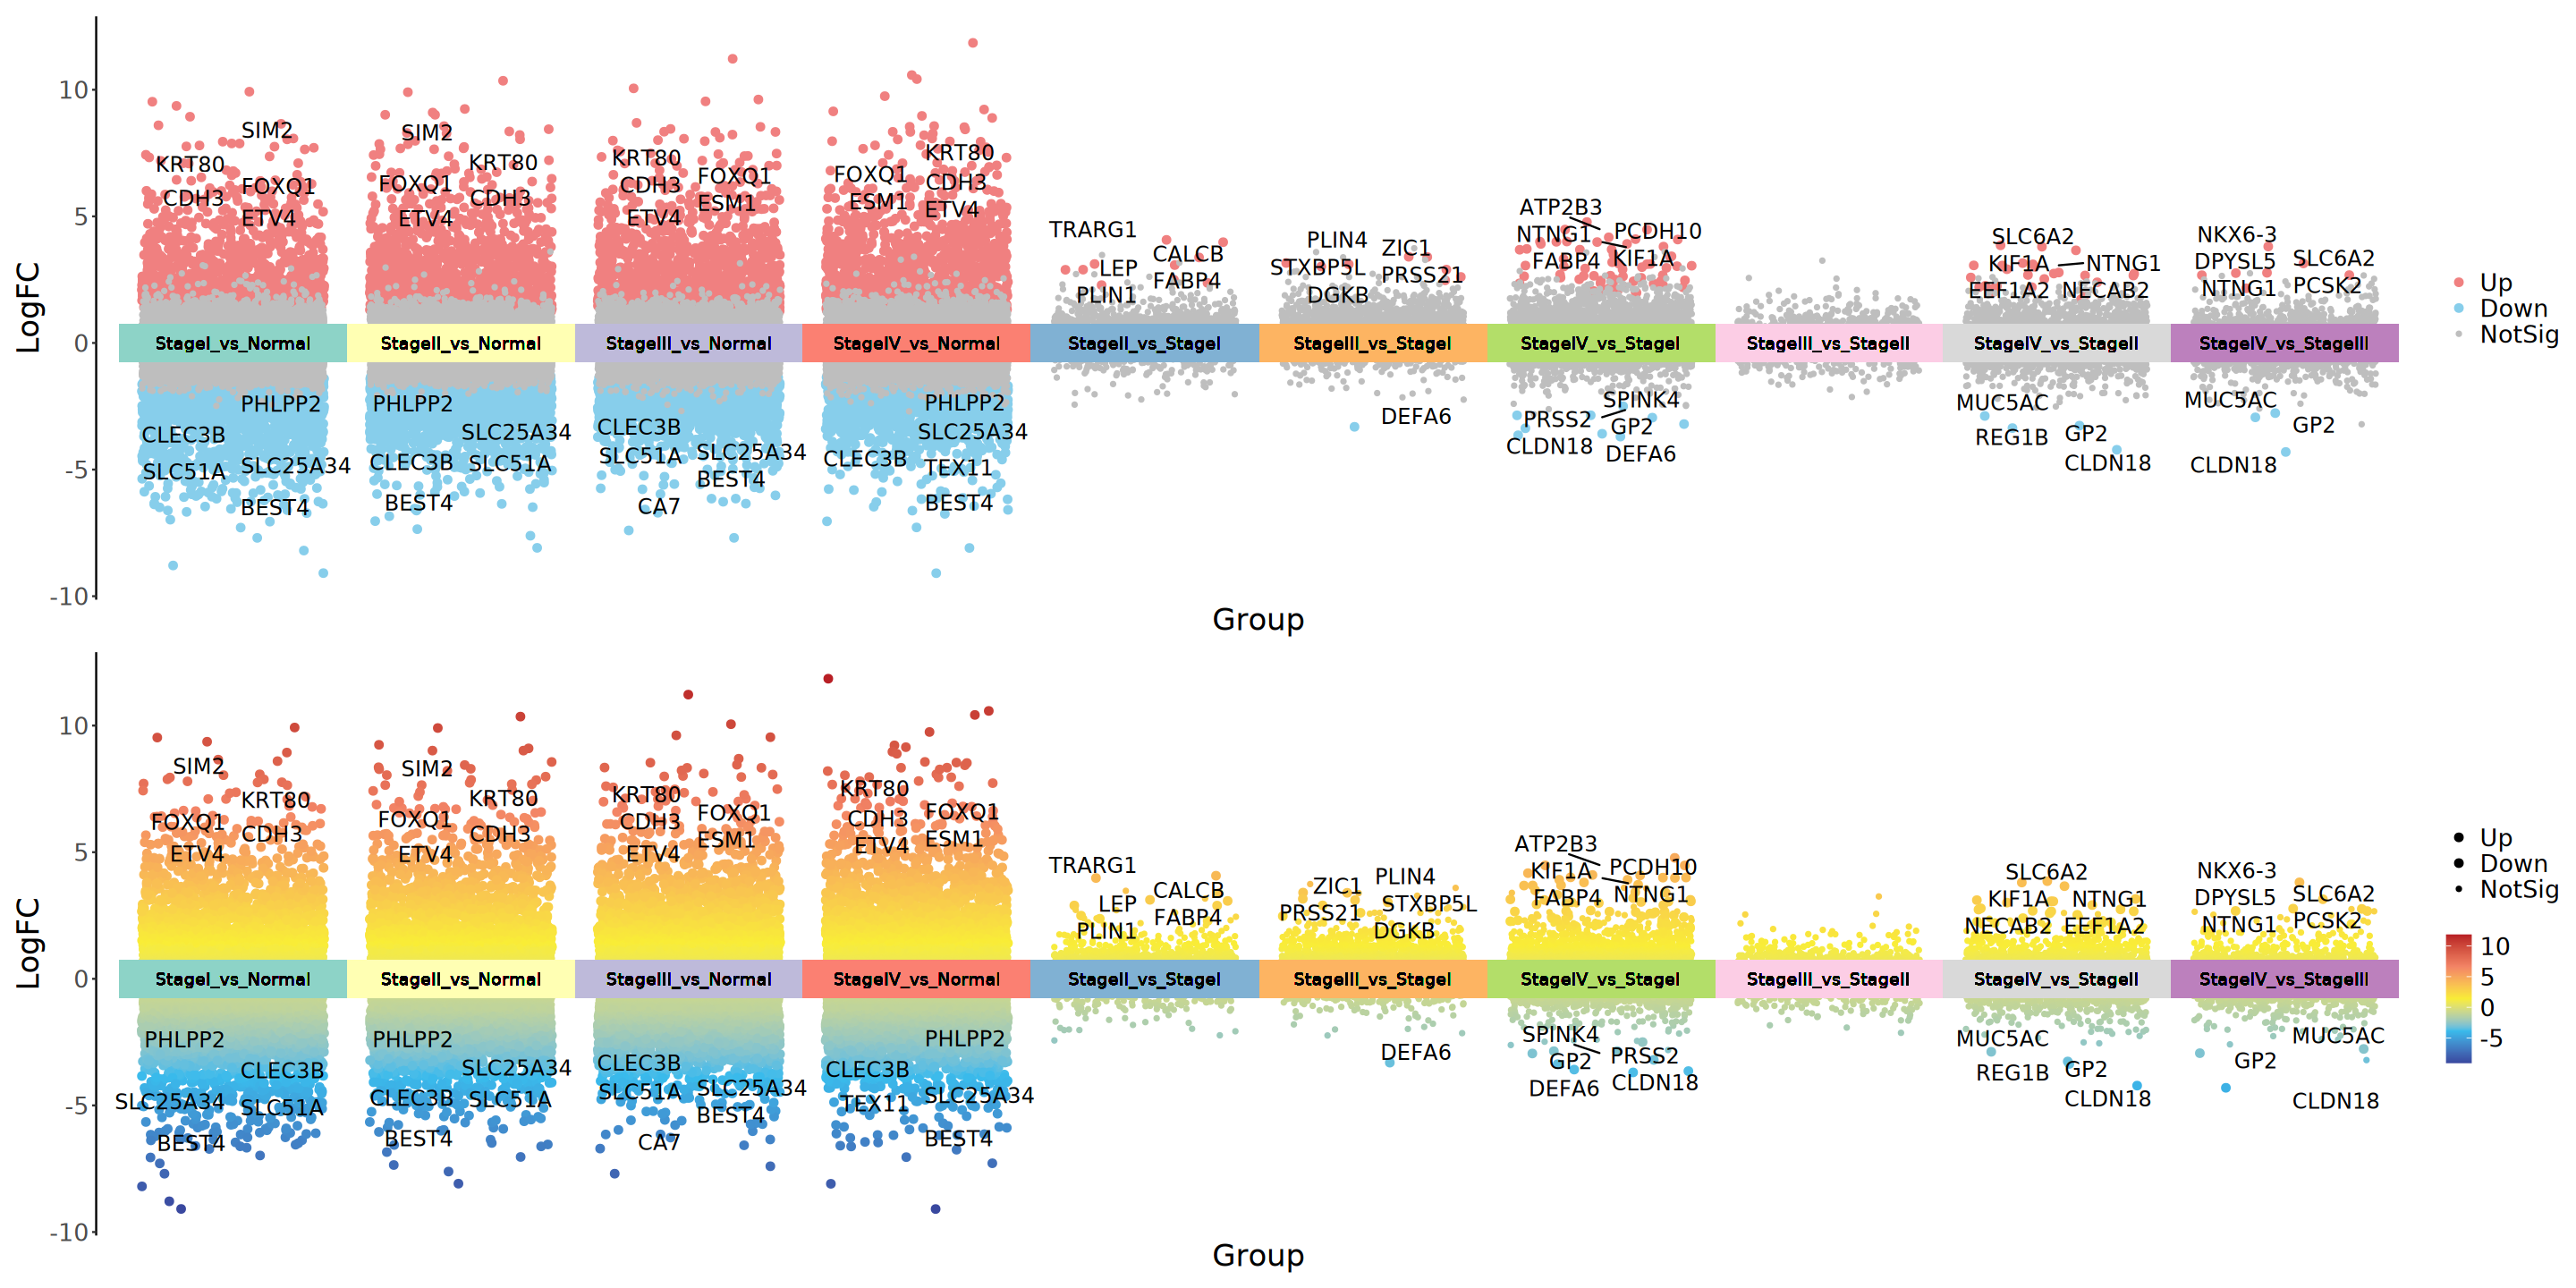

In [36]:
options(repr.plot.width = 24, repr.plot.height = 12)
p1 / p2

In [53]:
suppressPackageStartupMessages(library(ggVennDiagram))
suppressPackageStartupMessages(library(UpSetR))

In [48]:
genes_up <- list(res_deseq2[res_deseq2$class == "StageI_vs_Normal" & res_deseq2$deg == "Up", "gene_name"],
                 res_deseq2[res_deseq2$class == "StageII_vs_Normal" & res_deseq2$deg == "Up", "gene_name"],
                 res_deseq2[res_deseq2$class == "StageIII_vs_Normal" & res_deseq2$deg == "Up", "gene_name"],
                 res_deseq2[res_deseq2$class == "StageIV_vs_Normal" & res_deseq2$deg == "Up", "gene_name"])
genes_up <- setNames(genes_up, c("Stage I", "Stage II", "Stage III", "Stage IV"))
genes_up <- lapply(genes_up, unique)

In [49]:
genes_down <- list(res_deseq2[res_deseq2$class == "StageI_vs_Normal" & res_deseq2$deg == "Down", "gene_name"],
                   res_deseq2[res_deseq2$class == "StageII_vs_Normal" & res_deseq2$deg == "Down", "gene_name"],
                   res_deseq2[res_deseq2$class == "StageIII_vs_Normal" & res_deseq2$deg == "Down", "gene_name"],
                   res_deseq2[res_deseq2$class == "StageIV_vs_Normal" & res_deseq2$deg == "Down", "gene_name"])
genes_down <- setNames(genes_down, c("Stage I", "Stage II", "Stage III", "Stage IV"))
genes_down <- lapply(genes_down, unique)

In [50]:
fill_colors <- brewer.pal(n = length(genes_up), name = "Set2")

In [51]:
p1 <- ggVennDiagram(genes_up, 
              set_color = fill_colors, set_size = 6, 
              label_color = "firebrick", label_size = 5) +
    scale_fill_distiller(palette = "Reds", direction = 1)
p2 <- ggVennDiagram(genes_down, 
              set_color = fill_colors, set_size = 6, 
              label_color = "firebrick", label_size = 5) +
    scale_fill_distiller(palette = "Reds", direction = 1)

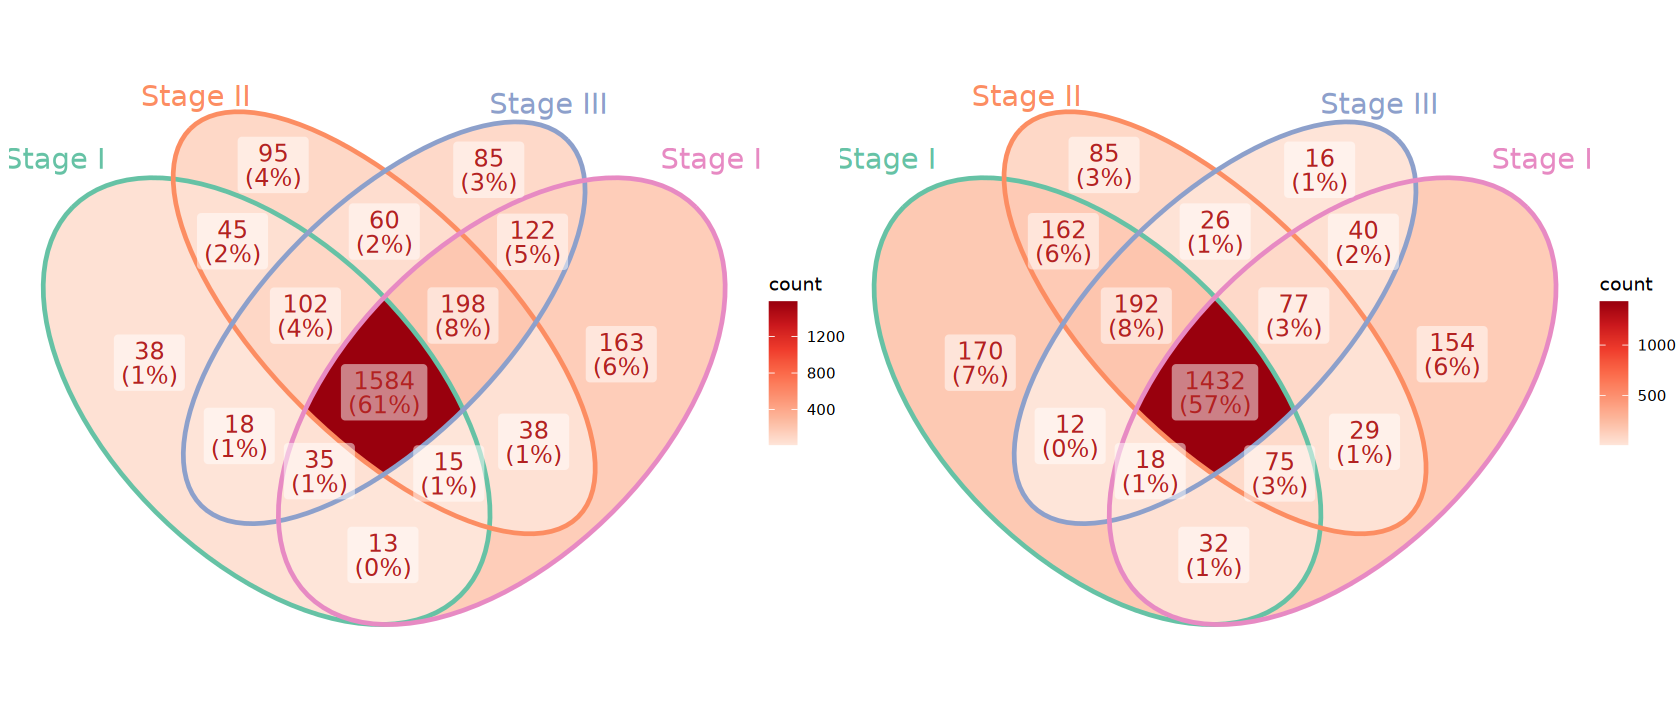

In [52]:
options(repr.plot.width = 14, repr.plot.height = 6)
p1 + p2

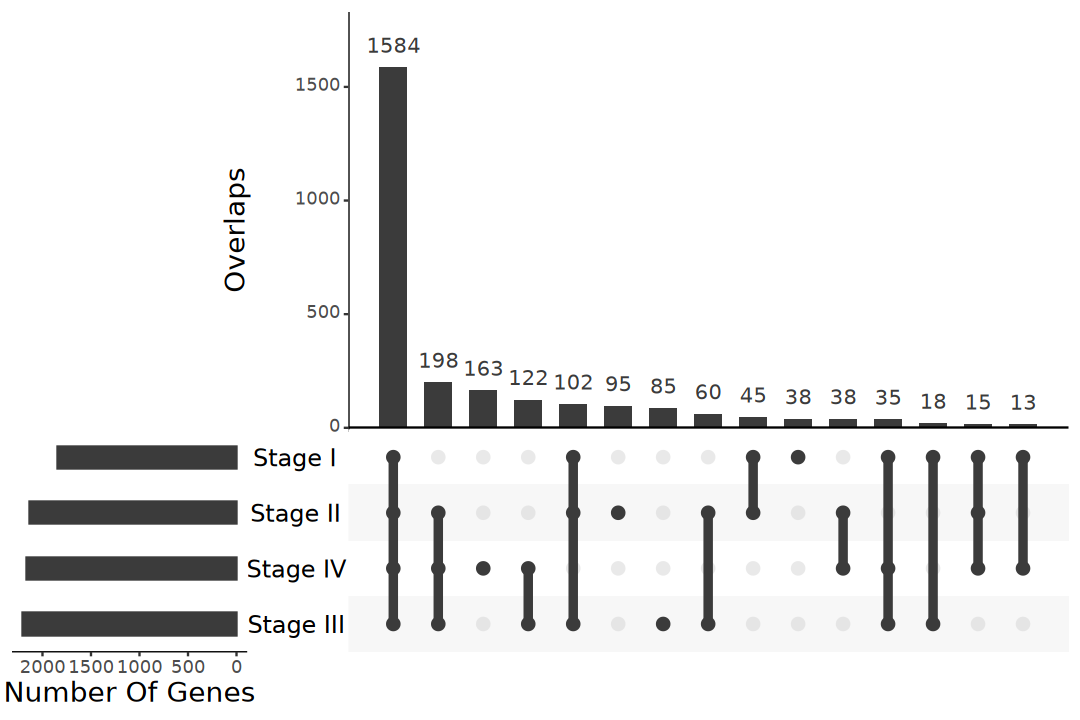

In [54]:
options(repr.plot.width = 9, repr.plot.height = 6)
upset(fromList(genes_up), sets.x.label = "Number Of Genes", mainbar.y.label = "Overlaps", 
      order.by = "freq", keep.order = TRUE, mb.ratio = c(0.6, 0.4), 
      point.size = 3.5, line.size = 2, text.scale = c(2, 1.5, 2, 1.5, 2, 2))

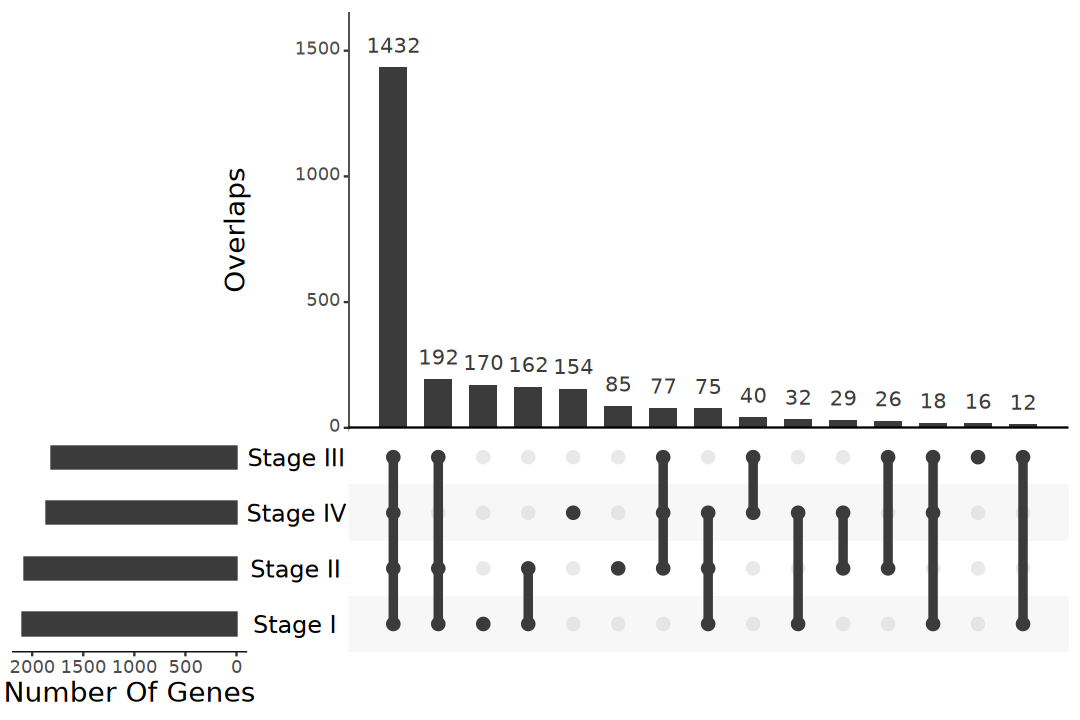

In [55]:
options(repr.plot.width = 9, repr.plot.height = 6)
upset(fromList(genes_down), sets.x.label = "Number Of Genes", mainbar.y.label = "Overlaps", 
      order.by = "freq", keep.order = TRUE, mb.ratio = c(0.6, 0.4), 
      point.size = 3.5, line.size = 2, text.scale = c(2, 1.5, 2, 1.5, 2, 2))